# Introduction to the OpenAlex API

OpenAlex is an open research information system containing information about scholarly works, authors, institutions, topics, sources, and other parts of the research landscape.

In this workbook, we will use the OpenAlex API to:

- retrieve information about a single publication
- inspect the JSON returned by the API
- search for publications about a research topic
- select useful information from the search results
- create a pandas DataFrame
- make a simple visualization

The goal is to become comfortable accessing and exploring OpenAlex data programmatically. Later exercises can build on these techniques to investigate more complicated research landscape questions.


## 1. Setup

We will use:

- `requests` to communicate with the OpenAlex API
- `pandas` to work with tabular data
- `matplotlib` through pandas for a simple visualization

OpenAlex provides free API keys. Add your OpenAlex API key below before running the examples.

**Do not publish your API key in a public repository.**


In [2]:
import requests
import pandas as pd

#API_KEY = "YOUR_OPENALEX_API_KEY"

BASE_URL = "https://api.openalex.org"


## 2. Retrieve a Single Publication

We will begin with one known publication.

OpenAlex assigns an identifier to each work in its database. If we know the OpenAlex work ID, we can request that record directly.

The example below uses an OpenAlex work ID. This can be replaced with another work selected during the OpenAlex web-interface portion of the workshop.


In [3]:
WORK_ID = "W2741809807"

url = f"{BASE_URL}/works/{WORK_ID}"

response = requests.get(
    url,
    #params={"api_key": API_KEY}
)

response.raise_for_status()

work = response.json()


### Look at the JSON

Before extracting anything, look at the complete response.

The JSON returned by the API becomes Python data structures that we can inspect and manipulate.


In [4]:
work


{'id': 'https://openalex.org/W2741809807',
 'doi': 'https://doi.org/10.7717/peerj.4375',
 'title': 'The state of OA: a large-scale analysis of the prevalence and impact of Open Access articles',
 'display_name': 'The state of OA: a large-scale analysis of the prevalence and impact of Open Access articles',
 'publication_year': 2018,
 'publication_date': '2018-02-13',
 'ids': {'openalex': 'https://openalex.org/W2741809807',
  'doi': 'https://doi.org/10.7717/peerj.4375',
  'mag': '2741809807',
  'pmid': 'https://pubmed.ncbi.nlm.nih.gov/29456894',
  'pmcid': 'https://www.ncbi.nlm.nih.gov/pmc/articles/5815332'},
 'language': 'en',
 'primary_location': {'id': 'doi:10.7717/peerj.4375',
  'doi': 'https://doi.org/10.7717/peerj.4375',
  'is_oa': True,
  'landing_page_url': 'https://doi.org/10.7717/peerj.4375',
  'pdf_url': None,
  'source': {'id': 'https://openalex.org/S1983995261',
   'display_name': 'PeerJ',
   'issn_l': '2167-8359',
   'issn': ['2167-8359'],
   'is_oa': True,
   'is_in_doaj'

A single OpenAlex work is represented as a Python dictionary.


In [5]:
type(work)


dict

We can see the fields available in the record by looking at its keys.


In [6]:
work.keys()


dict_keys(['id', 'doi', 'title', 'display_name', 'publication_year', 'publication_date', 'ids', 'language', 'primary_location', 'volume', 'type', 'is_traditional', 'indexed_in', 'open_access', 'authorships', 'institutions', 'countries_distinct_count', 'institutions_distinct_count', 'corresponding_author_ids', 'corresponding_institution_ids', 'apc_list', 'apc_paid', 'fwci', 'has_fulltext', 'cited_by_count', 'citation_normalized_percentile', 'cited_by_percentile_year', 'biblio', 'is_retracted', 'is_paratext', 'is_xpac', 'primary_topic', 'topics', 'keywords', 'concepts', 'mesh', 'locations_count', 'locations', 'best_oa_location', 'sustainable_development_goals', 'study_designs', 'awards', 'funders', 'has_content', 'content_urls', 'referenced_works_count', 'referenced_works', 'related_works', 'abstract_inverted_index', 'counts_by_year', 'updated_date', 'created_date'])

Now retrieve a few individual values.


In [7]:
print("Title:", work.get("title"))
print("Publication year:", work.get("publication_year"))
print("Type:", work.get("type"))
print("Cited by:", work.get("cited_by_count"))
print("DOI:", work.get("doi"))


Title: The state of OA: a large-scale analysis of the prevalence and impact of Open Access articles
Publication year: 2018
Type: article
Cited by: 1487
DOI: https://doi.org/10.7717/peerj.4375


### Authors

Some fields contain nested information. For example, the `authorships` field contains information about the authors associated with the publication.


In [8]:
work["authorships"]


[{'author_position': 'first',
  'author': {'id': 'https://openalex.org/A5048491430',
   'display_name': 'Heather Piwowar',
   'orcid': 'https://orcid.org/0000-0003-1613-5981',
   'observed_orcids': ['https://orcid.org/0000-0003-1613-5981']},
  'institutions': [{'id': 'https://openalex.org/I4200000001',
    'display_name': 'OpenAlex',
    'ror': 'https://ror.org/02nr0ka47',
    'country_code': 'CA',
    'type': 'nonprofit',
    'lineage': ['https://openalex.org/I4200000001']}],
  'countries': ['CA'],
  'is_corresponding': True,
  'raw_author_name': 'Heather Piwowar',
  'raw_affiliation_strings': ['Impactstory, Sanford, NC, USA'],
  'raw_orcid': None,
  'affiliations': [{'raw_affiliation_string': 'Impactstory, Sanford, NC, USA',
    'institution_ids': ['https://openalex.org/I4200000001']}]},
 {'author_position': 'middle',
  'author': {'id': 'https://openalex.org/A5023888391',
   'display_name': 'Jason R Priem',
   'orcid': 'https://orcid.org/0000-0001-6187-6610',
   'observed_orcids': ['

We can loop through the authorships and print the author names.


In [9]:
for authorship in work["authorships"]:
    print(authorship["author"]["display_name"])


Heather Piwowar
Jason R Priem
Vincent Larivière
Juan Pablo Alperín
Lisa Matthias
Bree Norlander
Ashley Farley
Jevin D. West
Stefanie Haustein


### Topics

OpenAlex also associates works with research topics.


In [10]:
work["topics"]


[{'id': 'https://openalex.org/T13607',
  'display_name': 'Academic Publishing and Open Access',
  'score': 0.6416000127792358,
  'subfield': {'id': 'https://openalex.org/subfields/3309',
   'display_name': 'Library and Information Sciences'},
  'field': {'id': 'https://openalex.org/fields/33',
   'display_name': 'Social Sciences'},
  'domain': {'id': 'https://openalex.org/domains/2',
   'display_name': 'Social Sciences'}},
 {'id': 'https://openalex.org/T10102',
  'display_name': 'scientometrics and bibliometrics research',
  'score': 0.32710000872612,
  'subfield': {'id': 'https://openalex.org/subfields/3309',
   'display_name': 'Library and Information Sciences'},
  'field': {'id': 'https://openalex.org/fields/33',
   'display_name': 'Social Sciences'},
  'domain': {'id': 'https://openalex.org/domains/2',
   'display_name': 'Social Sciences'}},
 {'id': 'https://openalex.org/T13516',
  'display_name': 'Publishing and Scholarly Communication',
  'score': 0.024399999529123306,
  'subfiel

In [11]:
for topic in work.get("topics", []):
    print(topic["display_name"])


Academic Publishing and Open Access
scientometrics and bibliometrics research
Publishing and Scholarly Communication


At this point, we have not performed an analysis. We have simply learned how to retrieve a record and investigate what information OpenAlex provides about it.


## 3. Search OpenAlex for a Research Topic

Often we do not begin with a known publication. Instead, we want to find research related to a subject.

OpenAlex allows us to search its Works endpoint using ordinary search terms.

The variable below is deliberately easy to change. After completing the example, try replacing it with a research topic that interests you.


In [12]:
TOPIC = "Nonlinear optimization supply chain"


In [14]:
params = {
    "search": TOPIC,
    "per-page": 50,
    #"api_key": API_KEY
}

response = requests.get(
    f"{BASE_URL}/works",
    params=params
)

response.raise_for_status()

data = response.json()


## 4. Inspect the Search Results

As before, start by looking at the JSON rather than immediately converting it into a table.


In [15]:
data


{'meta': {'notice': 'No API key, so this request shares one free daily budget ($0.10) with everyone on your network\'s IP address. Get a free key with its own $1/day at https://openalex.org/settings/api and add api_key=YOUR_KEY to your requests. An AI agent can get one for its user in one call: POST https://api.openalex.org/api-keys with {"email": "<your user\'s email>"}; we email them a link, and the key works once they click it. Docs for agents: https://help.openalex.org/llms.txt',
  'count': 140952,
  'db_response_time_ms': 184,
  'page': 1,
  'per_page': 50,
  'groups_count': None,
  'x_query': {'oql': 'get works with (Nonlinear optimization supply chain) in the title, abstract, or full text',
   'x_new_oql': 'get works with (Nonlinear optimization supply chain) in the title, abstract, or full text',
   'oqo': {'get_rows': 'works',
    'filter_rows': [{'column_id': 'fulltext.search',
      'value': 'Nonlinear optimization supply chain',
      'operator': 'has'}]},
   'url': '/works

A search response has a different structure from the single-work response.

Let's inspect its top-level keys.


In [16]:
data.keys()


dict_keys(['meta', 'results', 'group_by'])

The `meta` section contains information about the search response.


In [17]:
data["meta"]


{'notice': 'No API key, so this request shares one free daily budget ($0.10) with everyone on your network\'s IP address. Get a free key with its own $1/day at https://openalex.org/settings/api and add api_key=YOUR_KEY to your requests. An AI agent can get one for its user in one call: POST https://api.openalex.org/api-keys with {"email": "<your user\'s email>"}; we email them a link, and the key works once they click it. Docs for agents: https://help.openalex.org/llms.txt',
 'count': 140952,
 'db_response_time_ms': 184,
 'page': 1,
 'per_page': 50,
 'groups_count': None,
 'x_query': {'oql': 'get works with (Nonlinear optimization supply chain) in the title, abstract, or full text',
  'x_new_oql': 'get works with (Nonlinear optimization supply chain) in the title, abstract, or full text',
  'oqo': {'get_rows': 'works',
   'filter_rows': [{'column_id': 'fulltext.search',
     'value': 'Nonlinear optimization supply chain',
     'operator': 'has'}]},
  'url': '/works?filter=fulltext.sear

The actual work records are stored in `results`.


In [18]:
type(data["results"])


list

In [19]:
len(data["results"])


50

Look at the first work returned by the search.


In [20]:
data["results"][0]


{'id': 'https://openalex.org/W2031199960',
 'doi': 'https://doi.org/10.1109/icmecg.2012.43',
 'title': 'Dynamic Performance Optimization of the Supply Chain with Nonlinear Constraints',
 'display_name': 'Dynamic Performance Optimization of the Supply Chain with Nonlinear Constraints',
 'relevance_score': 92.28925,
 'publication_year': 2012,
 'publication_date': '2012-10-01',
 'ids': {'openalex': 'https://openalex.org/W2031199960',
  'doi': 'https://doi.org/10.1109/icmecg.2012.43',
  'mag': '2031199960'},
 'language': 'en',
 'primary_location': {'id': 'doi:10.1109/icmecg.2012.43',
  'doi': 'https://doi.org/10.1109/icmecg.2012.43',
  'is_oa': False,
  'landing_page_url': 'https://doi.org/10.1109/icmecg.2012.43',
  'pdf_url': None,
  'source': {'id': 'https://openalex.org/S4306419649',
   'display_name': 'International Conference on Management of e-Commerce and e-Government',
   'issn_l': None,
   'issn': None,
   'is_oa': False,
   'is_in_doaj': False,
   'is_core': False,
   'listed_in'

And print the titles of the first ten results.


In [21]:
for work in data["results"][:10]:
    print(work["title"])


Dynamic Performance Optimization of the Supply Chain with Nonlinear Constraints
Production Change Optimization Model of Nonlinear Supply Chain System under Emergencies
Research on AIGC-based Supply Chain Inventory Demand Forecasting Model and Nonlinear Optimization Strategy
Cost, quality, and safety: A nonlinear programming approach to optimize the temperature during supply chain of leafy greens
Designing closed-loop supply chains with nonlinear dimensioning factors using ant colony optimization
Dynamic analysis and management optimization for maritime supply chains using nonlinear control theory
Nonlinear multi-objective optimization model for a biomass direct-fired power generation supply chain using a case study in China
Logistics network design and optimization of closed-loop supply chain based on mixed integer nonlinear programming model
Development of a Graphical-user Interface to Optimize the Temperature for the Supply Chain of Leafy Greens Using Nonlinear Programming
A nonlinea

### Single record versus search results

Notice the difference:

- requesting a specific work returned one dictionary describing that work
- searching for works returned metadata plus a list of work records

This pattern is common when working with APIs.


## 5. Build a pandas DataFrame

Each OpenAlex work contains many fields. We usually do not need all of them for a particular analysis.

For this example, we will select only a few fields:

- title
- publication year
- citation count
- work type
- DOI
- OpenAlex ID

Selecting fields explicitly also makes it easier to see how information moves from nested JSON into a tabular dataset.


In [22]:
records = []

for work in data["results"]:
    records.append({
        "title": work.get("title"),
        "year": work.get("publication_year"),
        "citations": work.get("cited_by_count"),
        "type": work.get("type"),
        "doi": work.get("doi"),
        "openalex_id": work.get("id")
    })

df = pd.DataFrame(records)

df.head()


,title,year,citations,type,doi,openalex_id
0,Dynamic Performance Optimization of the Supply...,2012,1,conference-paper,https://doi.org/10.1109/icmecg.2012.43,https://openalex.org/W2031199960
1,Production Change Optimization Model of Nonlin...,2023,9,article,https://doi.org/10.3390/s23073718,https://openalex.org/W4362560030
2,Research on AIGC-based Supply Chain Inventory ...,2025,0,article,https://doi.org/10.61091/jcmcc127b-176,https://openalex.org/W4409603855
3,"Cost, quality, and safety: A nonlinear program...",2016,22,article,https://doi.org/10.1016/j.lwt.2016.06.037,https://openalex.org/W2422699046
4,Designing closed-loop supply chains with nonli...,2014,19,article,https://doi.org/10.1007/s00500-014-1405-7,https://openalex.org/W1972307178


Inspect the size and columns of the DataFrame.


In [23]:
df.shape


(50, 6)

In [24]:
df.columns


Index(['title', 'year', 'citations', 'type', 'doi', 'openalex_id'], dtype='object')

We can now use ordinary pandas operations to explore the records returned by the API.

For example, sort the results by citation count.


In [25]:
df.sort_values(
    "citations",
    ascending=False
)[["title", "year", "citations"]].head(10)


,title,year,citations
32,Supply Chain Coordination and Influenza Vaccin...,2008,232
24,Facility Location and Supply Chain Optimizatio...,2011,197
19,Design of Sustainable Product Systems and Supp...,2013,179
48,Modeling and optimizing the integrated problem...,2013,177
38,Mixed-Integer Nonlinear Programming Models and...,2008,159
26,Simulation and optimization of supply chains: ...,2008,128
45,Joint optimization for coordinated configurati...,2015,128
39,A supply chain network design considering tran...,2011,103
22,Transfer Prices for Multienterprise Supply Cha...,2001,102
35,An optimization approach for supply chain mana...,2006,93


## 6. Publications by Year

Let's count how many of the retrieved search results were published in each year.


In [26]:
works_by_year = (
    df["year"]
    .value_counts()
    .sort_index()
)

works_by_year


2001    2
2003    1
2004    1
2006    2
2008    3
2009    3
2010    1
2011    2
2012    3
2013    4
2014    2
2015    2
2016    3
2017    4
2018    1
2019    2
2020    3
2021    2
2023    1
2024    1
2025    4
2026    3
Name: year, dtype: int64

Now create a simple bar chart.


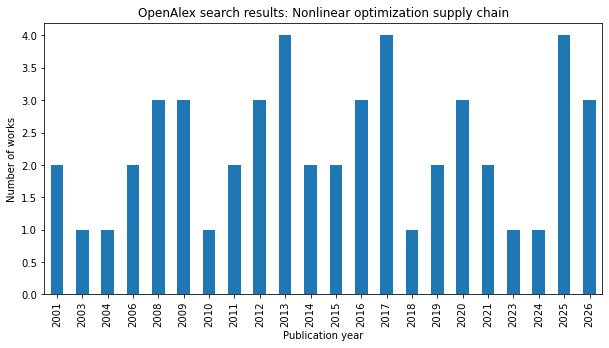

In [27]:
works_by_year.plot(
    kind="bar",
    xlabel="Publication year",
    ylabel="Number of works",
    title=f"OpenAlex search results: {TOPIC}",
    figsize=(10, 5)
);


### A note about interpretation

This chart describes the records returned by **this API request**.

It should not yet be interpreted as a complete research landscape or as a definitive measure of research activity in this field.

Among other things, we have not yet considered:

- how the search query defines the research topic
- how OpenAlex determines relevance
- pagination and retrieving larger result sets
- database coverage
- additional filters such as dates, institutions, authors, or OpenAlex topics

Those issues become important when we move from learning how to use an API to designing a research landscape analysis.


## 7. Try Your Own Research Topic

Now change the value of `TOPIC` and rerun the topic-search sections of the workbook.

For example:

```python
TOPIC = "CAR T-cell therapy"
```

or:

```python
TOPIC = "Alzheimer's disease biomarkers"
```

Better yet, choose a subject from your own research, professional work, or area of interest.

After rerunning the search, consider:

1. Do the returned publications appear relevant to your topic?
2. What kinds of publications are being returned?
3. Which results have the highest citation counts?
4. What does the publication-by-year chart look like?
5. What other information in the JSON might be useful for investigating this research area?
6. What would you want to change or add before treating these results as a research landscape?


## 8. What We Did

In this workbook, we followed a simple computational research workflow:

**Publication → API request → JSON**

and then:

**Research topic → API search → JSON → selected fields → pandas DataFrame → visualization**

The important goal is not the particular example topic. Once you understand the pattern, you can change the query and begin exploring research areas that interest you.

Later workbooks can build on this foundation by using more structured searches, filters, larger result sets, researchers, institutions, funding information, and relationships among research entities.
